# 05 · Attention and Transformers: Letting Residues Talk to Their Partners

## Overview

Every model in Notebooks 01–04 flattened the interface into a list of 4,886 numbers. An MLP's first layer gives each number its own private weights, so it cannot know that 60 of those numbers describe the *same* RBD residue, or that residue K417 pairs with ACE2 D30. Biology is relational: **which residue interacts with which partner** is the question.

**Attention** answers it. Each element of a set computes a weighted average of other elements, with weights computed from the data. The idea came from machine translation (Bahdanau, Cho & Bengio, 2014), where a decoder RNN learned to "look back" at the relevant source words. "Attention Is All You Need" (Vaswani *et al.*, 2017) then dropped recurrence altogether. The resulting **transformer** is now the backbone of protein language models (ESM), structure prediction (AlphaFold 2/3) and generative design (RFdiffusion).

**A brief history of the bottleneck**

| Year | Model | Limitation |
|---|---|---|
| 1986–97 | RNNs, LSTMs | Process one element at a time; a whole sequence squeezed into one hidden vector |
| 2014 | RNN + attention | The decoder can look back at every input element, but computation is still sequential |
| 2017 | Transformer | Pure attention: every element attends to every other in parallel |
| 2021 | AlphaFold 2 (Evoformer) | Attention over residues *and* residue pairs, with pair features biasing attention |

## Learning objectives

1. Implement scaled dot-product attention and multi-head attention from scratch.
2. Explain why attention is permutation-equivariant, and how positional/identity embeddings break that symmetry.
3. Represent an MD frame as residue **tokens** plus a **pair** feature, and build an ACE2↔RBD cross-attention transformer.
4. Test the architecture honestly: find a task where its inductive bias actually pays off.
5. Read attention maps as residue–residue relevance, and compare them with Notebook 01's attributions.

**Runtime:** about 8 minutes on a laptop CPU.

In [1]:
import sys, time, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
sys.path.insert(0, ".")
from ppi_dl.data import load_ppi, set_seed
from ppi_dl.plotting import plot_residue_importance, top_residues

data = load_ppi("block")
iface = data.interface
print(data.summary())
print(f"{iface.n_ace2} ACE2 tokens, {iface.n_rbd} RBD tokens, {len(iface.pair_ace2_idx)} contacting pairs "
      f"({len(iface.pair_ace2_idx) / (iface.n_ace2 * iface.n_rbd):.1%} of all ACE2 x RBD combinations)")

split=block: train (3200, 4886), test (800, 4886), train class counts [1600, 1600], test class counts [400, 400]
233 ACE2 tokens, 156 RBD tokens, 4886 contacting pairs (13.4% of all ACE2 x RBD combinations)


## 1. Scaled dot-product attention, by hand

Each token $i$ emits a **query** $q_i$ ("what am I looking for?"), a **key** $k_j$ ("what do I offer?") and a **value** $v_j$ ("what I pass on"). These are three linear projections of the token's features. Token $i$'s output is a weighted average of values, with weights given by query–key similarity:

$$ \text{Attention}(Q, K, V) = \operatorname{softmax}\!\Big(\frac{QK^\top}{\sqrt{d_k}} + B\Big)V $$

* Dividing by $\sqrt{d_k}$ keeps the logits' variance near 1, so the softmax does not saturate as dimension grows.
* $B$ is an optional **bias** added to the logits. We will use it for pair features and masks, exactly as AlphaFold does.
* In **self-attention**, $Q$, $K$ and $V$ come from the same set. In **cross-attention**, queries come from one set (RBD residues) and keys/values from another (ACE2 residues).

Notice the link to the projection critic in Notebook 03: there, too, a score was an inner product between a learned embedding and features.

In [2]:
def attention(q, k, v, bias=None):
    """q: (..., n_q, d), k/v: (..., n_k, d). Returns output and the attention weights."""
    logits = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    if bias is not None:
        logits = logits + bias
    w = torch.softmax(logits, dim=-1)
    return w @ v, w

# a toy check: 3 queries, 4 keys
set_seed(0)
q, k, v = torch.randn(3, 8), torch.randn(4, 8), torch.randn(4, 8)
out, w = attention(q, k, v)
print("output", tuple(out.shape), "| each row of weights sums to", w.sum(-1).numpy().round(3))

# permutation equivariance: shuffling keys/values together does not change the output
perm = torch.tensor([2, 0, 3, 1])
out_p, _ = attention(q, k[perm], v[perm])
print("same output after shuffling keys/values:", torch.allclose(out, out_p, atol=1e-6))

output (3, 8) | each row of weights sums to [1. 1. 1.]
same output after shuffling keys/values: True


**Attention treats its inputs as a set.** Reordering the keys changes nothing. That suits an interface, which has no natural order, but it also means the model cannot tell tokens apart unless we tell it. Transformers on text add **positional encodings**. Here each token receives a learned **residue-identity embedding** (which ACE2 or RBD position it is). Because RBD tokens are aligned between the two viruses (Notebook 01), the same embedding describes the same structural position in SARS-CoV and SARS-CoV-2.

> We deliberately do **not** give the model the amino-acid identity of each residue. The two RBDs differ in sequence, so the identities alone would solve the classification. The model must instead separate the variants from **interface geometry and dynamics**, which is what we want it to explain.

### Multi-head attention

One attention pattern captures one kind of relationship. **Multi-head** attention runs $h$ attentions in parallel on lower-dimensional projections and concatenates the results, so different heads can specialize (for example, salt bridges versus hydrophobic packing).

In [3]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        assert d % heads == 0
        self.h, self.dk = heads, d // heads
        self.q, self.k, self.v, self.o = (nn.Linear(d, d) for _ in range(4))
    def split(self, x):                       # (B, n, d) -> (B, h, n, dk)
        B, n, _ = x.shape
        return x.view(B, n, self.h, self.dk).transpose(1, 2)
    def forward(self, x_q, x_kv, bias=None):
        q, k, v = self.split(self.q(x_q)), self.split(self.k(x_kv)), self.split(self.v(x_kv))
        out, w = attention(q, k, v, bias)
        B, h, n, dk = out.shape
        return self.o(out.transpose(1, 2).reshape(B, n, h * dk)), w

## 2. Tokenizing an MD frame

We turn each frame into two sets of tokens and one pair feature:

* **ACE2 tokens** $a_i$ ($i = 1..233$): the row of the inverse-distance contact map (the residue's distances to all RBD residues; zero where never in contact), projected to $d$ dimensions, plus the residue-identity embedding.
* **RBD tokens** $r_j$ ($j = 1..156$): the corresponding column, projected and embedded the same way.
* **Pair feature** $p_{ij}$: the standardized inverse distance for each of the 4,886 contacting pairs.

Then the layers:

1. **Cross-attention RBD → ACE2** with logits biased by a learned function of $p_{ij}$, and **masked** to pairs that ever come into contact. Restricting attention to a contact graph makes this layer a **graph attention network** (Veličković *et al.*, 2018). Transformers and GNNs are close relatives.
2. **Self-attention among RBD residues**, so the RBD can integrate what each of its residues learned.
3. Mean-pool the RBD tokens and classify.

Every residue shares the same weights. The model therefore has far fewer parameters than the MLP, which is the inductive bias we will test.

In [4]:
# dense (233 x 156) contact maps for every frame; missing pairs filled with 0
M_tr, MASK = iface.to_pair_matrix(data.X_train)
M_te, _ = iface.to_pair_matrix(data.X_test)
M_tr, M_te = torch.tensor(M_tr), torch.tensor(M_te)
mask_bias = torch.zeros(iface.n_rbd, iface.n_ace2)
mask_bias[~torch.tensor(MASK).T] = float("-inf")        # RBD queries x ACE2 keys
ytr, yte = torch.tensor(data.y_train), torch.tensor(data.y_test)
print("contact-map tensors:", tuple(M_tr.shape), tuple(M_te.shape))

class Block(nn.Module):
    """Pre-norm transformer block: attention + feed-forward, both residual."""
    def __init__(self, d, heads):
        super().__init__()
        self.n1, self.n_kv, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d), nn.LayerNorm(d)
        self.att = MultiHeadAttention(d, heads)
        self.ff = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Linear(2 * d, d))
    def forward(self, x, kv=None, bias=None):
        kv = x if kv is None else kv
        h, w = self.att(self.n1(x), self.n_kv(kv), bias)
        x = x + h
        return x + self.ff(self.n2(x)), w

class InterfaceTransformer(nn.Module):
    def __init__(self, d=64, heads=4, n_self=2, n_classes=2):
        super().__init__()
        self.heads = heads
        self.ace_in = nn.Linear(iface.n_rbd, d)
        self.rbd_in = nn.Linear(iface.n_ace2, d)
        self.ace_id = nn.Parameter(0.02 * torch.randn(iface.n_ace2, d))   # residue-identity embeddings
        self.rbd_id = nn.Parameter(0.02 * torch.randn(iface.n_rbd, d))
        self.pair_bias = nn.Sequential(nn.Linear(1, 16), nn.GELU(), nn.Linear(16, heads))
        self.cross = Block(d, heads)
        self.selfs = nn.ModuleList([Block(d, heads) for _ in range(n_self)])
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, n_classes))

    def forward(self, M, return_attn=False):          # M: (B, 233, 156)
        a = self.ace_in(M) + self.ace_id               # (B, 233, d)
        r = self.rbd_in(M.transpose(1, 2)) + self.rbd_id   # (B, 156, d)
        pb = self.pair_bias(M.transpose(1, 2).unsqueeze(-1)).permute(0, 3, 1, 2)  # (B, h, 156, 233)
        r, w_cross = self.cross(r, kv=a, bias=pb + mask_bias)
        for blk in self.selfs:
            r, _ = blk(r)
        logits = self.head(r.mean(1))
        return (logits, w_cross) if return_attn else logits

model = InterfaceTransformer()
n_tf = sum(p.numel() for p in model.parameters())
n_mlp = 4886 * 256 + 256 + 256 * 64 + 64 + 64 * 2 + 2
print(f"InterfaceTransformer parameters: {n_tf:,}   (Notebook 01 MLP: {n_mlp:,})")

contact-map tensors: (3200, 233, 156) (800, 233, 156)
InterfaceTransformer parameters: 151,078   (Notebook 01 MLP: 1,267,650)


## 3. Does the architecture actually help?

A new architecture has to earn its place. We test it twice: on the classification task from
Notebook 01, and on a task that needs residue structure.

In [5]:
def fit(model, X, y, epochs, bs=32, lr=1e-3, wd=1e-2):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(X))
        for i in range(0, len(X), bs):
            idx = perm[i:i + bs]
            loss = F.cross_entropy(model(X[idx]), y[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval(); return model

@torch.no_grad()
def evaluate(model, X, y, bs=256):
    logits = torch.cat([model(X[i:i + bs]) for i in range(0, len(X), bs)])
    return (logits.argmax(1) == y).float().mean().item(), F.cross_entropy(logits, y).item()

class MLP(nn.Module):
    def __init__(self, d_in, dropout=0.3, out=2):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, 256), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(256, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, out))
    def forward(self, x):
        return self.net(x)

# dense (233 x 156) contact maps for every frame; missing pairs filled with 0
M_tr, MASK = iface.to_pair_matrix(data.X_train)
M_te, _ = iface.to_pair_matrix(data.X_test)
M_tr, M_te = torch.tensor(M_tr), torch.tensor(M_te)
mask_bias = torch.zeros(iface.n_rbd, iface.n_ace2)
mask_bias[~torch.tensor(MASK).T] = float("-inf")        # RBD queries x ACE2 keys
ytr, yte = torch.tensor(data.y_train), torch.tensor(data.y_test)
Xtr_f, Xte_f = torch.tensor(data.X_train), torch.tensor(data.X_test)

set_seed(0); t0 = time.time()
tf = fit(InterfaceTransformer(), M_tr, ytr, epochs=8)
acc_tf, ce_tf = evaluate(tf, M_te, yte)
set_seed(0)
mlp_cls = fit(MLP(data.n_features), Xtr_f, ytr, epochs=8, bs=32)
acc_mlp, ce_mlp = evaluate(mlp_cls, Xte_f, yte)
pd.DataFrame({"parameters": [n_tf, sum(p.numel() for p in mlp_cls.parameters())],
              "test accuracy": [acc_tf, acc_mlp], "test cross-entropy": [ce_tf, ce_mlp]},
             index=["InterfaceTransformer", "flat MLP"]).round(4)

,parameters,test accuracy,test cross-entropy
InterfaceTransformer,151078,1.0000,0.0001
flat MLP,1267650,0.9987,0.0093


Both reach the ceiling. As Notebook 01 established, separating the two variants is *easy*:
their RBD sequences differ and many contacts shift systematically, so a linear model already
gets 99%. **A saturated task cannot tell two architectures apart**, no matter how different
they are. The only visible difference is that the transformer does it with about 8× fewer
parameters.

To see what the architecture buys, we need a task that genuinely requires knowing which
residue is which.

### Masked reconstruction: the ESM/AlphaFold training signal

Hide a random 15% of the **RBD residues** (zero out their whole column of the contact map)
and ask the model to reconstruct those contacts from the residues that remain. This is
exactly the self-supervised objective behind protein language models, transferred to an
interface. It needs the model to know *which* residue is missing and *who its neighbours
are* — precisely the structure a flat MLP discards.

We give both architectures the same objective, the same masks and the same budget. The flat
MLP sees the masked frame plus an explicit 156-long indicator of which residues were hidden,
so it is not denied any information; it simply has no built-in notion of a residue.

In [6]:
pair_mask_t = torch.tensor(MASK).T                      # (156, 233) measured pairs

class MaskedInterfaceModel(InterfaceTransformer):
    def __init__(self, d=64, heads=4):
        super().__init__(d, heads)
        self.recon = nn.Linear(d, iface.n_ace2)
    def forward(self, M, rbd_mask):                     # rbd_mask: (B, 156) True = hidden
        M_in = M * (~rbd_mask).unsqueeze(1)             # hide whole RBD columns
        a = self.ace_in(M_in) + self.ace_id
        r = self.rbd_in(M_in.transpose(1, 2)) + self.rbd_id
        pb = self.pair_bias(M_in.transpose(1, 2).unsqueeze(-1)).permute(0, 3, 1, 2)
        r, _ = self.cross(r, kv=a, bias=pb + mask_bias)
        for blk in self.selfs:
            r, _ = blk(r)
        return self.recon(r)                            # (B, 156, 233): predicted columns

class MaskedMLP(nn.Module):
    """Flat baseline: masked frame + mask indicator -> all 156 x 233 pair values."""
    def __init__(self, hidden=512):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(iface.n_ace2 * iface.n_rbd + iface.n_rbd, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, iface.n_rbd * iface.n_ace2))
    def forward(self, M, rbd_mask):
        M_in = M * (~rbd_mask).unsqueeze(1)
        z = torch.cat([M_in.transpose(1, 2).reshape(len(M), -1), rbd_mask.float()], 1)
        return self.net(z).view(len(M), iface.n_rbd, iface.n_ace2)

def masked_batch_loss(model, M, hide):
    pred = model(M, hide)
    target = M.transpose(1, 2)
    sel = hide.unsqueeze(-1) & pair_mask_t
    return ((pred - target) ** 2)[sel].mean()

def train_masked(model, epochs=5, p=0.15, bs=32, lr=1e-3):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    for ep in range(epochs):
        perm = torch.randperm(len(M_tr))
        for i in range(0, len(M_tr), bs):
            Mb = M_tr[perm[i:i + bs]]
            loss = masked_batch_loss(model, Mb, torch.rand(len(Mb), iface.n_rbd) < p)
            opt.zero_grad(); loss.backward(); opt.step()
    return model.eval()

recon = {}
for name, builder in [("InterfaceTransformer", MaskedInterfaceModel), ("flat MLP", MaskedMLP)]:
    set_seed(0); t0 = time.time()
    m = train_masked(builder())
    set_seed(1)
    hide_te = torch.rand(len(M_te), iface.n_rbd) < 0.15          # identical masks for both
    with torch.no_grad():
        mse = masked_batch_loss(m, M_te, hide_te).item()
        base = ((M_te.transpose(1, 2) ** 2)[hide_te.unsqueeze(-1) & pair_mask_t]).mean().item()
    recon[name] = {"parameters": sum(p.numel() for p in m.parameters()),
                   "held-out masked MSE": mse, "seconds": time.time() - t0}
    if name == "InterfaceTransformer":
        mm = m
recon["predict the mean (zeros)"] = {"parameters": 0, "held-out masked MSE": base, "seconds": 0.0}
recon_tab = pd.DataFrame(recon).T
recon_tab["variance explained"] = 1 - recon_tab["held-out masked MSE"] / base
print("the flat MLP uses %.0fx more parameters than the transformer"
      % (recon["flat MLP"]["parameters"] / recon["InterfaceTransformer"]["parameters"]))
recon_tab.round(3)

the flat MLP uses 226x more parameters than the transformer


,parameters,held-out masked MSE,seconds,variance explained
InterfaceTransformer,166223.0,0.401,73.613,0.627
flat MLP,37599740.0,0.420,25.568,0.609
predict the mean (zeros),0.0,1.075,0.000,0.000


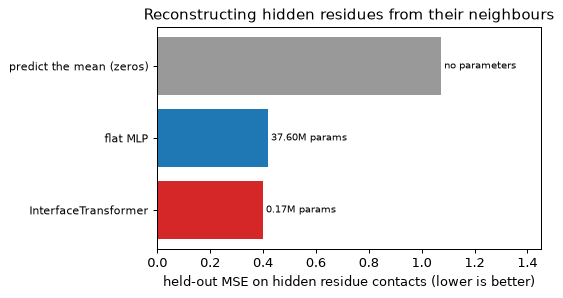

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 3.2))
names = ["predict the mean (zeros)", "flat MLP", "InterfaceTransformer"]
vals = [recon[n]["held-out masked MSE"] for n in names]
ax.barh(range(3), vals, color=["0.6", "tab:blue", "tab:red"])
for i, n in enumerate(names):
    p = recon[n]["parameters"]
    ax.text(vals[i] + 0.01, i, f"{p/1e6:.2f}M params" if p else "no parameters", va="center", fontsize=8)
ax.set_yticks(range(3)); ax.set_yticklabels(names, fontsize=9); ax.invert_yaxis()
ax.set_xlim(0, max(vals) * 1.35)
ax.set_xlabel("held-out MSE on hidden residue contacts (lower is better)")
ax.set_title("Reconstructing hidden residues from their neighbours"); plt.show()

Now the comparison means something, though not in the way a bigger-is-better intuition would
predict. The "variance explained" column is the fraction of the hidden contacts' variance each
model recovers, where predicting the average frame scores 0. The transformer reconstructs
slightly **better** than the flat MLP while using a tiny fraction of the parameters (the ratio
is printed above the table).

That ratio is the whole point. Operating on a flat vector forces the MLP to spend a weight on
every (input pixel, output pixel) pair: its first and last layers alone account for almost all
of its parameters, and it must learn from 3,200 frames that input 1,742 and output 1,742 are
the same physical quantity. The transformer gets that for free. Every residue is a token
processed by **shared** weights, and the contact mask tells it which partners exist, so
knowledge learned about one residue transfers to all the others. This is the same
inductive-bias argument that lets AlphaFold-style models generalize from comparatively few
experimental structures — and note that the advantage appeared only once we asked a question
that depends on residue identity.

## 4. Reading the attention

attention is highly peaked: the top 1% of pairs carry 43% of the weight


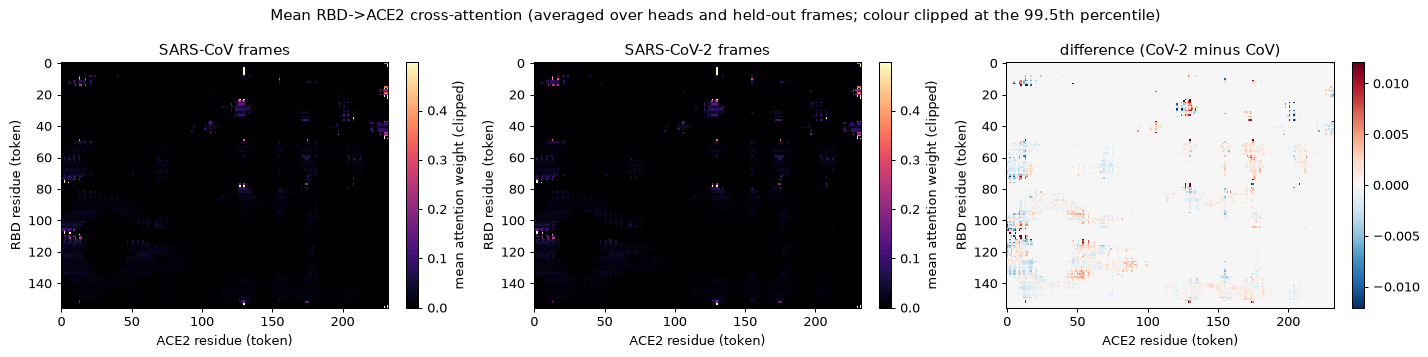

In [8]:
@torch.no_grad()
def mean_cross_attention(model, M, bs=200):
    acc = torch.zeros(iface.n_rbd, iface.n_ace2)
    for i in range(0, len(M), bs):
        _, w = model(M[i:i + bs], return_attn=True)    # (B, heads, 156, 233)
        acc += w.mean(1).sum(0)
    return (acc / len(M)).numpy()

A_cov1 = mean_cross_attention(tf, M_te[yte == 0])
A_cov2 = mean_cross_attention(tf, M_te[yte == 1])
print("attention is highly peaked: the top 1%% of pairs carry %.0f%% of the weight"
      % (100 * np.sort(A_cov2.ravel())[::-1][:int(0.01 * A_cov2.size)].sum() / A_cov2.sum()))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
vmax = np.percentile(A_cov2[A_cov2 > 0], 99.5)
for ax, A, t in [(axes[0], A_cov1, "SARS-CoV frames"), (axes[1], A_cov2, "SARS-CoV-2 frames")]:
    im = ax.imshow(A, aspect="auto", cmap="magma", vmin=0, vmax=vmax, interpolation="nearest")
    fig.colorbar(im, ax=ax, fraction=0.04, label="mean attention weight (clipped)")
    ax.set_title(t)
d = A_cov2 - A_cov1
lim = np.percentile(np.abs(d), 99.9)
im = axes[2].imshow(d, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim, interpolation="nearest")
fig.colorbar(im, ax=axes[2], fraction=0.04)
axes[2].set_title("difference (CoV-2 minus CoV)")
for ax in axes:
    ax.set_xlabel("ACE2 residue (token)"); ax.set_ylabel("RBD residue (token)")
fig.suptitle("Mean RBD->ACE2 cross-attention (averaged over heads and held-out frames; colour clipped at the 99.5th percentile)")
fig.tight_layout(); plt.show()

Each row is a probability distribution over one RBD residue's contacts, and the maps are
sparse: most of the weight sits on a handful of partners. The colour scale is clipped at the
99.5th percentile, because on a linear 0–1 scale a few saturated pixels would hide everything
else.

Attention weights describe how the model *routes* information. They are not a measurement of
causal importance (Jain & Wallace, 2019), so we also compute **integrated gradients** for the
transformer, the same attribution used for the MLP in Notebook 01.

integrated gradients in 51s


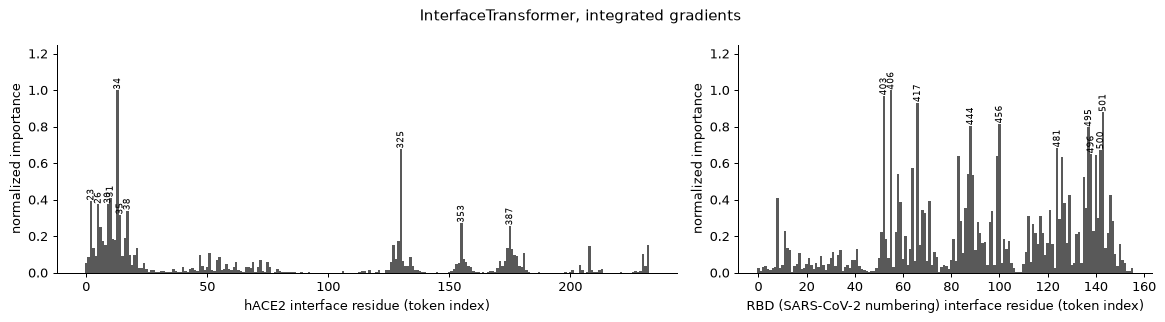

In [9]:
def ig_pairs(model, M, steps=16, bs=100):
    model.eval(); total = torch.zeros(iface.n_ace2, iface.n_rbd)
    for i in range(0, len(M), bs):
        X = M[i:i + bs]; g = torch.zeros_like(X)
        for a in torch.linspace(0, 1, steps + 1)[1:]:
            Xa = (a * X).requires_grad_(True)
            out = model(Xa); (out[:, 1] - out[:, 0]).sum().backward()
            g += Xa.grad
        total += (X * g / steps).abs().sum(0)
    return (total / len(M)).numpy()[iface.pair_ace2_idx, iface.pair_rbd_idx]   # back to 4,886 pairs

t0 = time.time()
ig_tf = ig_pairs(tf, M_te)
print(f"integrated gradients in {time.time()-t0:.0f}s")
attn_pair = np.abs(A_cov2 - A_cov1).T[iface.pair_ace2_idx, iface.pair_rbd_idx]

Xg = Xte_f.clone(); g = torch.zeros_like(Xg)
for a in torch.linspace(0, 1, 17)[1:]:
    Xa = (a * Xg).requires_grad_(True); o = mlp_cls(Xa); (o[:, 1] - o[:, 0]).sum().backward(); g += Xa.grad
ig_mlp = (Xg * g / 16).abs().mean(0).numpy()

fig, _ = plot_residue_importance(iface, ig_tf, title="InterfaceTransformer, integrated gradients"); plt.show()

In [10]:
from scipy.stats import spearmanr

cands = {"MLP integrated grad.": ig_mlp, "Transformer integrated grad.": ig_tf,
         "Transformer |attention difference|": attn_pair}
names = list(cands)
pair_rho = pd.DataFrame([[spearmanr(cands[a], cands[b])[0] for b in names] for a in names],
                        index=names, columns=names)
# residue-level scores, summed over pairs (the convention used throughout this series)
rbd_scores = {k: iface.residue_importance(v)[1] for k, v in cands.items()}
top20 = {k: set(np.argsort(v)[::-1][:20]) for k, v in rbd_scores.items()}
overlap = pd.DataFrame([[len(top20[a] & top20[b]) for b in names] for a in names],
                       index=names, columns=names)
display(pair_rho.round(2).rename_axis("Spearman, all 4,886 pairs"))
display(overlap.rename_axis("shared RBD residues among each method's top 20"))

# external check: ACE2-contacting RBD residues seen in the crystal structure (Lan et al., Nature 2020)
CRYSTAL = [417, 446, 449, 453, 455, 456, 475, 486, 487, 489, 493, 496, 498, 500, 501, 502, 505]
rbd_ids = iface.rbd_resids["cov2"]
crystal_tokens = {i for i, r in enumerate(rbd_ids) if r in CRYSTAL}
chance = 20 * len(crystal_tokens) / len(rbd_ids)
hits = pd.DataFrame({"crystal contacts in top 20": [len(top20[k] & crystal_tokens) for k in names],
                     "expected by chance": round(chance, 1)}, index=names)
display(hits)

ace_top, rbd_top = top_residues(iface, ig_tf, k=10)
pd.DataFrame({"ACE2": [r for r, _ in ace_top], "ACE2 score": [s for _, s in ace_top],
              "RBD (CoV-2 #)": [r for r, _ in rbd_top], "RBD score": [s for _, s in rbd_top]})

,MLP integrated grad.,Transformer integrated grad.,Transformer |attention difference|
"Spearman, all 4,886 pairs",,,
MLP integrated grad.,1.00,0.2,0.11
Transformer integrated grad.,0.20,1.0,0.10
Transformer |attention difference|,0.11,0.1,1.00


,MLP integrated grad.,Transformer integrated grad.,Transformer |attention difference|
shared RBD residues among each method's top 20,,,
MLP integrated grad.,20,15,12
Transformer integrated grad.,15,20,9
Transformer |attention difference|,12,9,20


,crystal contacts in top 20,expected by chance
MLP integrated grad.,10,2.2
Transformer integrated grad.,9,2.2
Transformer |attention difference|,8,2.2


,ACE2,ACE2 score,RBD (CoV-2 #),RBD score
0,34,1.000,406,1.000
1,325,0.677,403,0.969
2,31,0.410,417,0.932
3,23,0.392,501,0.879
4,30,0.376,456,0.815
5,26,0.375,444,0.806
6,38,0.340,495,0.797
7,35,0.316,481,0.684
8,353,0.271,500,0.674
9,387,0.257,496,0.651


**The methods disagree, and that is worth taking seriously.** Read the three tables in order.

**Individual pairs: low agreement.** Rank correlation across all 4,886 pairs is weak. Two
architectures that both reach near-perfect accuracy are relying on noticeably different
contacts, and the attention difference is not a stand-in for either gradient attribution. The
reason is that the task is easy and the features are highly correlated: many different subsets
of contacts suffice to separate the variants, so each model settles on one of them. (This is
exactly why the NIGMS module drops highly correlated columns before ranking features.)

**Residues: much better agreement.** Once pair scores are summed onto residues, the methods'
top-20 lists overlap substantially. Summing averages out the arbitrary choice of *which*
contact of a residue a given model happened to use. This is why per-residue importance, not
per-pair importance, is the scientifically meaningful output — and it justifies the
aggregation the NIGMS module performs.

**The external check is the one that counts.** The last table compares each method's top 20
RBD residues against the ACE2 contacts seen in the crystal structure (Lan *et al.*, 2020),
alongside the number expected if 20 residues were drawn at random. All three methods are
enriched several-fold over chance, which is evidence that they are finding real interface
biology rather than a quirk of one architecture. Agreement with independent structural data is
a far stronger claim than two models agreeing with each other.

## 5. From here to AlphaFold

The model above already contains, in miniature, three ideas at the heart of modern structural biology models:

| Idea in this notebook | Where it appears at scale |
|---|---|
| Residue tokens + residue-identity embeddings | ESM protein language models (one token per amino acid) |
| A **pair** feature biasing attention logits | AlphaFold 2 Evoformer and AlphaFold 3 Pairformer ("pair bias") |
| Attention masked to a contact graph | Graph neural networks; ProteinMPNN's k-nearest-neighbour graphs |
| Cross-attention between two partners | Antibody–antigen and binder–target models |

AlphaFold 2 adds **triangle updates** to the pair representation. If $i$ is near $j$ and $j$ is near $k$, that constrains $i$–$k$, so pair features are updated using the third edges of triangles. That is the subject of one of the papers in this repository's `research_papers/` folder ("Triangle multiplication is all you need for biomolecular structure representations").

So far we have used attention to *understand* the interface. In **Notebook 06** we put the transformer *inside* a diffusion model, so that it **generates** interface frames residue by residue. That is the recipe of AlphaFold 3's structure module and of RFdiffusion.

## Challenge Problem 1: What does the pair bias buy?

Create a version of `InterfaceTransformer` whose cross-attention uses **only the contact mask** (no learned pair bias): replace `bias=pb + mask_bias` with `bias=mask_bias`. Retrain on the full block split for 8 epochs and compare (a) test cross-entropy and (b) the Spearman correlation of its integrated-gradient pair scores with `ig_tf`.

In [11]:
# Start your code here

### Challenge Problem 1 Solution

In [12]:
class NoPairBias(InterfaceTransformer):
    def forward(self, M, return_attn=False):
        a = self.ace_in(M) + self.ace_id
        r = self.rbd_in(M.transpose(1, 2)) + self.rbd_id
        r, w = self.cross(r, kv=a, bias=mask_bias)
        for blk in self.selfs:
            r, _ = blk(r)
        logits = self.head(r.mean(1))
        return (logits, w) if return_attn else logits

set_seed(0)
tf_nb = fit(NoPairBias(), M_tr, ytr, epochs=8)
acc_nb, ce_nb = evaluate(tf_nb, M_te, yte)
ig_nb = ig_pairs(tf_nb, M_te)
pd.DataFrame({"test acc": [acc_tf, acc_nb], "test CE": [ce_tf, ce_nb],
              "Spearman(IG, ig_tf)": [1.0, spearmanr(ig_nb, ig_tf)[0]]},
             index=["with pair bias", "mask only"]).round(4)

,test acc,test CE,"Spearman(IG, ig_tf)"
with pair bias,1.0,0.0001,1.0000
mask only,1.0,0.0001,0.7949


## Challenge Problem 2: Which residues are predictable from their neighbours?

Section 3 trained `mm`, a transformer that reconstructs hidden residues' contacts. Use it to
hide **one RBD residue at a time** (for a subset of held-out frames) and record the
reconstruction error for each. Which residues are easiest to infer from their neighbours, and
which are hardest? Relate the answer to how many contacts each residue has.

In [13]:
# Start your code here

### Challenge Problem 2 Solution

Spearman(number of contacts, reconstruction error) = 0.33


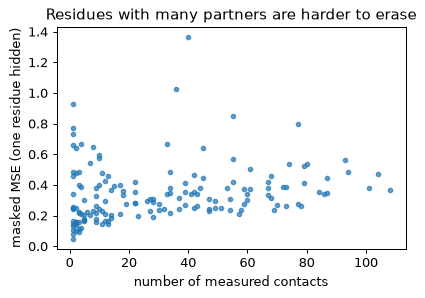

,easiest residue,easiest contacts,easiest masked MSE,hardest residue,hardest contacts,hardest masked MSE
47,395.0,1.0,0.050,NaN,NaN,NaN
2,338.0,1.0,0.082,466.0,1.0,0.928
19,361.0,3.0,0.096,NaN,NaN,NaN
16,358.0,2.0,0.100,NaN,NaN,NaN
1,337.0,1.0,0.104,441.0,36.0,1.027
46,394.0,3.0,0.114,NaN,NaN,NaN
44,392.0,4.0,0.122,NaN,NaN,NaN
154,515.0,1.0,0.129,NaN,NaN,NaN
0,NaN,NaN,NaN,442.0,40.0,1.365
3,NaN,NaN,NaN,443.0,55.0,0.848


In [14]:
sub = M_te[::8]
per_res = []
with torch.no_grad():
    for j in range(iface.n_rbd):
        hide = torch.zeros(len(sub), iface.n_rbd, dtype=torch.bool); hide[:, j] = True
        sel = pair_mask_t[j]
        if sel.sum() == 0:
            per_res.append(np.nan); continue
        err = ((mm(sub, hide)[:, j, sel] - sub.transpose(1, 2)[:, j, sel]) ** 2).mean()
        per_res.append(err.item())

n_contacts = np.bincount(iface.pair_rbd_idx, minlength=iface.n_rbd)
pr = pd.DataFrame({"residue": iface.rbd_resids["cov2"], "contacts": n_contacts,
                   "masked MSE": per_res}).dropna().sort_values("masked MSE")
print("Spearman(number of contacts, reconstruction error) = %.2f"
      % spearmanr(pr["contacts"], pr["masked MSE"])[0])
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.scatter(pr["contacts"], pr["masked MSE"], s=12, alpha=0.7)
ax.set_xlabel("number of measured contacts"); ax.set_ylabel("masked MSE (one residue hidden)")
ax.set_title("Residues with many partners are harder to erase"); plt.show()
pd.concat([pr.head(8).add_prefix("easiest "), pr.tail(8).iloc[::-1].add_prefix("hardest ").reset_index(drop=True)], axis=1).round(3)

## Summary

* Attention computes data-dependent weighted averages over a set. It is permutation-equivariant, so identity or positional embeddings tell tokens apart.
* Representing the interface as residue tokens plus a pair feature, with attention restricted to contacts, gives a model with ~8× fewer parameters than the MLP.
* Classification on this dataset is saturated, so it cannot distinguish architectures. On masked reconstruction, a task that needs residue identity, the inductive bias pays off clearly.
* Attention maps show how the model routes information; gradient attributions give a complementary, like-for-like check.
* Two architectures with equal accuracy can rank features very differently. Validate attributions against independent structural evidence, not just against each other.
* Pair-biased attention, masked modelling and contact-graph attention are the building blocks of ESM, AlphaFold and RFdiffusion.

## References

* Bahdanau D., Cho K., Bengio Y. (2014) Neural machine translation by jointly learning to align and translate. arXiv:1409.0473.
* Vaswani A. *et al.* (2017) Attention is all you need. *NeurIPS*.
* Veličković P. *et al.* (2018) Graph attention networks. *ICLR*.
* Jain S., Wallace B. C. (2019) Attention is not explanation. *NAACL*.
* Jumper J. *et al.* (2021) Highly accurate protein structure prediction with AlphaFold. *Nature* 596, 583–589.
* Rives A. *et al.* (2021) Biological structure and function emerge from scaling unsupervised learning to 250 million protein sequences. *PNAS* 118, e2016239118.
* Dauparas J. *et al.* (2022) Robust deep learning–based protein sequence design using ProteinMPNN. *Science* 378, 49–56.